In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import linear_model
import joblib

In [22]:
data = pd.read_csv("telecom_customer_churn.csv")
zipcode = pd.read_csv("telecom_zipcode_population.csv")

In [23]:
data.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [24]:
zipcode.head()

,Zip Code,Population
0,90001,54492
1,90002,44586
2,90003,58198
3,90004,67852
4,90005,43019


In [47]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             7043 non-null   str    
 1   Age                                7043 non-null   int64  
 2   Married                            7043 non-null   str    
 3   Number of Dependents               7043 non-null   int64  
 4   City                               7043 non-null   str    
 5   Number of Referrals                7043 non-null   int64  
 6   Tenure in Months                   7043 non-null   int64  
 7   Offer                              3166 non-null   str    
 8   Phone Service                      7043 non-null   str    
 9   Avg Monthly Long Distance Charges  6361 non-null   float64
 10  Multiple Lines                     6361 non-null   str    
 11  Internet Service                   7043 non-null   str    
 12  Int

In [27]:
print(data["Customer Status"].count().sum())
print(data["Customer Status"].unique())
print(data['Customer Status'].value_counts())

7043
<StringArray>
['Stayed', 'Churned', 'Joined']
Length: 3, dtype: str
Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64


In [32]:
data["Offer"].value_counts()

Offer
Offer B    824
Offer E    805
Offer D    602
Offer A    520
Offer C    415
Name: count, dtype: int64

In [38]:
data = data.merge(zipcode, on='Zip Code', how='left')
data.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason,Population
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN,4498
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN,31297
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices,62069
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction,46677
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability,42853


In [44]:
droped = ['Customer ID','Longitude','Latitude','Zip Code','Total Charges','Total Refunds','Total Extra Data Charges','Total Long Distance Charges']

In [45]:
data.drop(droped,axis=1,inplace=True)

In [59]:
data.head()

,Gender,Age,Married,Number of Dependents,City,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,...,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Revenue,Customer Status,Churn Category,Churn Reason,Population
0,Female,37,Yes,0,Frazier Park,2,9,NaN,Yes,42.39,...,Yes,One Year,Yes,Credit Card,65.6,974.81,Stayed,NaN,NaN,4498
1,Male,46,No,0,Glendale,0,9,NaN,Yes,10.69,...,No,Month-to-Month,No,Credit Card,-4.0,610.28,Stayed,NaN,NaN,31297
2,Male,50,No,0,Costa Mesa,0,4,Offer E,Yes,33.65,...,Yes,Month-to-Month,Yes,Bank Withdrawal,73.9,415.45,Churned,Competitor,Competitor had better devices,62069
3,Male,78,Yes,0,Martinez,1,13,Offer D,Yes,27.82,...,Yes,Month-to-Month,Yes,Bank Withdrawal,98.0,1599.51,Churned,Dissatisfaction,Product dissatisfaction,46677
4,Female,75,Yes,0,Camarillo,3,3,NaN,Yes,7.38,...,Yes,Month-to-Month,Yes,Credit Card,83.9,289.54,Churned,Dissatisfaction,Network reliability,42853


In [68]:
x = data.drop(columns=['Customer Status'])
x.head()

,Gender,Age,Married,Number of Dependents,City,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,...,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Revenue,Churn Category,Churn Reason,Population
0,Female,37,Yes,0,Frazier Park,2,9,NaN,Yes,42.39,...,No,Yes,One Year,Yes,Credit Card,65.6,974.81,NaN,NaN,4498
1,Male,46,No,0,Glendale,0,9,NaN,Yes,10.69,...,Yes,No,Month-to-Month,No,Credit Card,-4.0,610.28,NaN,NaN,31297
2,Male,50,No,0,Costa Mesa,0,4,Offer E,Yes,33.65,...,No,Yes,Month-to-Month,Yes,Bank Withdrawal,73.9,415.45,Competitor,Competitor had better devices,62069
3,Male,78,Yes,0,Martinez,1,13,Offer D,Yes,27.82,...,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.0,1599.51,Dissatisfaction,Product dissatisfaction,46677
4,Female,75,Yes,0,Camarillo,3,3,NaN,Yes,7.38,...,No,Yes,Month-to-Month,Yes,Credit Card,83.9,289.54,Dissatisfaction,Network reliability,42853


In [69]:
y = data["Customer Status"]
y.head()

0     Stayed
1     Stayed
2    Churned
3    Churned
4    Churned
Name: Customer Status, dtype: str

In [90]:
gen = pd.get_dummies(x['Gender'],drop_first=True,dtype='uint8')
gen.head()

,Male
0,0
1,1
2,1
3,1
4,0


count    7043.000000
mean       46.509726
std        16.750352
min        19.000000
25%        32.000000
50%        46.000000
75%        60.000000
max        80.000000
Name: Age, dtype: float64


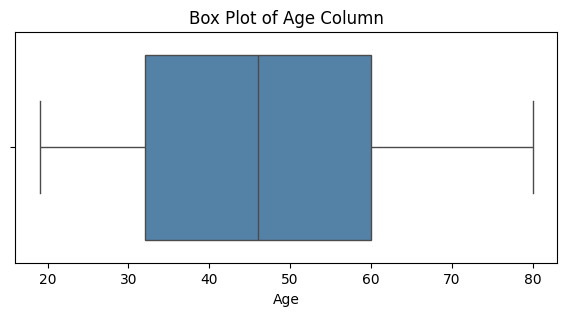

In [96]:
# Print exact summary stats (min, 25%, 50% median, 75%, max)
print(x['Age'].describe())

# Plot the single column
plt.figure(figsize=(7, 3))
sns.boxplot(x=x['Age'], color='steelblue')
plt.title('Box Plot of Age Column')
plt.xlabel('Age')
plt.show()


In [97]:
x['Age'].skew()

np.float64(0.1621864486741778)

In [100]:
x['Age'] = x['Age'].astype('uint8')
x['Age'].dtype

dtype('uint8')

In [109]:
mar = pd.get_dummies(x['Married'],drop_first=True,dtype='uint8')
mar.head()

,Yes
0,1
1,0
2,0
3,1
4,1


<Axes: ylabel='Number of Dependents'>

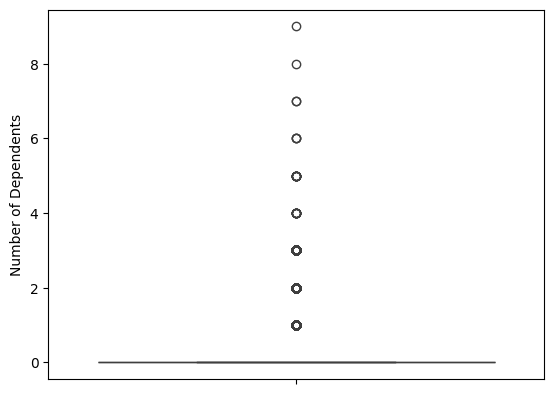

In [117]:
sns.boxplot(x['Number of Dependents'])

In [119]:
df = data[data['Customer Status'] != 'Joined'].copy()
df['Churn'] = (df['Customer Status'] == 'Churned').astype(int)

df['Has Dependents'] = (df['Number of Dependents'] > 0).map({True: 'Yes', False: 'No'})

print("Average dependents by Married:")
print(df.groupby('Married')['Number of Dependents'].mean().round(2))

print("\nCounts (Married vs Has Dependents):")
print(pd.crosstab(df['Married'], df['Has Dependents']))

print("\nRow percentages:")
print(pd.crosstab(df['Married'], df['Has Dependents'], normalize='index').round(2) * 100)

print("\nChurn rate (%) by Married and Has Dependents:")
print((df.groupby(['Married', 'Has Dependents'])['Churn'].mean() * 100).round(1))

Average dependents by Married:
Married
No     0.16
Yes    0.79
Name: Number of Dependents, dtype: float64

Counts (Married vs Has Dependents):
Has Dependents    No   Yes
Married                   
No              3011   260
Yes             2031  1287

Row percentages:
Has Dependents    No   Yes
Married                   
No              92.0   8.0
Yes             61.0  39.0

Churn rate (%) by Married and Has Dependents:
Married  Has Dependents
No       No                38.2
         Yes               19.2
Yes      No                30.2
         Yes                4.4
Name: Churn, dtype: float64


In [130]:
mar['Yes'].corr(x['Number of Dependents'])

np.float64(0.3242051367512027)

In [121]:
x['Number of Dependents'] = x['Number of Dependents'].astype('uint8')
x['Number of Dependents'].dtype

dtype('uint8')

In [126]:
x['City'].isna().sum()

np.int64(0)

In [135]:
x.drop(['City'],axis=1,inplace=True)

In [138]:
# Average Population for churned vs stayed (Joined customers excluded)
df = data[data['Customer Status'] != 'Joined']

print(df.groupby('Customer Status')['Population'].mean().round(0))

Customer Status
Churned    23957.0
Stayed     21388.0
Name: Population, dtype: float64
